# Project 21: Flight Delay Prediction and Rescheduling
## Task 2 — Exploratory Data Analysis & Leakage-Safe Feature Engineering

**Author:** Pranjal Modi (Student ID: `2401010334`)  
**Role:** Member 2 (EDA, Time-Series & Feature Engineering)  
**Phase:** Applied Machine Learning (AML) Phase 1  

---

### Module Overview
This notebook establishes the domain analysis and pre-departure feature space:
1. **Part A (Exploratory Data Analysis & Time Series):** Empirical delay distributions, diurnal hourly escalation ($26\% \rightarrow 52\%$ evening peak), day-of-week and monthly seasonal patterns.
2. **Part B (Feature Engineering & Chronological Partitions):** Trigonometric cyclical encodings (sin/cos for 4 temporal horizons), Out-Of-Fold Empirical Bayes target priors ($m=10$), and strict calendar-based data splitting (Train / Val / Frozen Test).


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Step 1: Environment Setup
# ═══════════════════════════════════════════════════════════════════════════
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path(os.path.abspath(".."))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns

from src.config import PROCESSED_DATA_DIR, RESULTS_DIR

# Plotting defaults
sns.set_theme(style="whitegrid", font_scale=1.1)
COLORS = sns.color_palette("muted")
FIGURES_DIR = RESULTS_DIR / "figures" / "eda"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"✓ Project Root: {PROJECT_ROOT}")
print(f"✓ Figures Dir:  {FIGURES_DIR}")

---
## 1. Load and Inspect the Cleaned Dataset

We load `flights_cleaned.csv` as prepared by Member 1B. Per the handoff:
- 16 columns retained (14 pre-departure features + `ARRIVAL_DELAY` + `DELAYED`)
- Cancelled and diverted flights have been excluded
- All 365 days of 2015 are covered
- `FLIGHT_DATE` in `YYYY-MM-DD` format for chronological sorting

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Step 2: Load Cleaned Dataset
# ═══════════════════════════════════════════════════════════════════════════
CLEANED_PATH = PROCESSED_DATA_DIR / "flights_cleaned.csv"
df = pd.read_csv(CLEANED_PATH, low_memory=False)
df["FLIGHT_DATE"] = pd.to_datetime(df["FLIGHT_DATE"])
df = df.sort_values(by="FLIGHT_DATE").reset_index(drop=True)

print("=" * 70)
print("CLEANED DATASET OVERVIEW")
print("=" * 70)
print(f"Shape:         {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Date Range:    {df['FLIGHT_DATE'].min().date()} to {df['FLIGHT_DATE'].max().date()}")
print(f"Memory:        {df.memory_usage(deep=True).sum() / 1e6:.2f} MB")
print(f"Duplicates:    {df.duplicated().sum()}")
print("=" * 70)

In [ ]:
# Column names and data types
print("\nColumn Data Types:")
print("-" * 50)
for col in df.columns:
    print(f"  {col:<25} {str(df[col].dtype):>12}")
print("\nFirst 5 rows:")
df.head()

### 1.1 Missing Values and Data Quality

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Step 3: Missing Values Audit
# ═══════════════════════════════════════════════════════════════════════════
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_report = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
missing_report = missing_report[missing_report["Missing Count"] > 0]

if len(missing_report) == 0:
    print("✓ No missing values in any column.")
else:
    print("⚠️ Columns with missing values:")
    print(missing_report.sort_values("Missing Count", ascending=False))

print(f"\nTotal missing cells: {df.isnull().sum().sum()}")
print(f"TAIL_NUMBER missing: {df['TAIL_NUMBER'].isnull().sum()} ({df['TAIL_NUMBER'].isnull().mean()*100:.2f}%)")
print(f"SCHEDULED_TIME missing: {df['SCHEDULED_TIME'].isnull().sum()}")

### 1.2 Target Definition Verification

The target `DELAYED` must satisfy:
- `DELAYED = 1` when `ARRIVAL_DELAY > 15` minutes
- `DELAYED = 0` when `ARRIVAL_DELAY ≤ 15` minutes

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Step 4: Verify Target Definition
# ═══════════════════════════════════════════════════════════════════════════
positive_check = (df.loc[df["DELAYED"] == 1, "ARRIVAL_DELAY"] > 15).all()
negative_check = (df.loc[df["DELAYED"] == 0, "ARRIVAL_DELAY"] <= 15).all()

print("Target Definition Verification:")
print(f"  All DELAYED=1 have ARRIVAL_DELAY > 15?  {'✓ PASS' if positive_check else '✗ FAIL'}")
print(f"  All DELAYED=0 have ARRIVAL_DELAY ≤ 15?  {'✓ PASS' if negative_check else '✗ FAIL'}")
print(f"\n  Target values: {sorted(df['DELAYED'].unique())}")
print(f"  No null targets: {df['DELAYED'].isnull().sum() == 0}")

### 1.3 Leakage Column Verification

Post-departure columns (actual times, actual delays, taxi times, etc.) must not be present
in the cleaned dataset's feature columns. `ARRIVAL_DELAY` is retained only as ground truth.

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Step 5: Leakage Column Audit
# ═══════════════════════════════════════════════════════════════════════════
POST_DEPARTURE_COLS = [
    "DEPARTURE_TIME", "DEPARTURE_DELAY", "TAXI_OUT", "WHEELS_OFF",
    "ELAPSED_TIME", "AIR_TIME", "WHEELS_ON", "TAXI_IN",
    "ARRIVAL_TIME", "CANCELLATION_REASON",
    "AIR_SYSTEM_DELAY", "SECURITY_DELAY", "AIRLINE_DELAY",
    "LATE_AIRCRAFT_DELAY", "WEATHER_DELAY", "DIVERTED", "CANCELLED"
]

present_leakage = [c for c in POST_DEPARTURE_COLS if c in df.columns]
if not present_leakage:
    print("✓ No post-departure leakage columns found in cleaned dataset.")
else:
    print(f"⚠️ LEAKAGE WARNING: {present_leakage}")

print("\n⚠️ Reminder: ARRIVAL_DELAY is in the dataset as ground truth only.")
print("   It must NEVER be used as a model input feature.")
print("   DELAYED is the classification target label.")

### 1.4 Cancellation and Diversion Handling

Per Member 1B's handoff:
- Cancelled flights (89,884 in full dataset / ~411 in sample) → excluded because arrival delay is undefined.
- Diverted flights (15,187 in full dataset / ~67 in sample) → excluded because destination dynamics are voided.
- This accounts for 100% of missing `ARRIVAL_DELAY` values. No valid completed flights were dropped.

In [ ]:
# Verify no cancelled/diverted flags remain
for col in ["CANCELLED", "DIVERTED"]:
    if col in df.columns:
        print(f"⚠️ {col} column still present: unique values = {df[col].unique()}")
    else:
        print(f"✓ {col} correctly removed from cleaned dataset.")

print(f"\n✓ All {len(df):,} rows have valid ARRIVAL_DELAY (no NaN): {df['ARRIVAL_DELAY'].isnull().sum() == 0}")

---
## 2. Target Distribution Analysis

### Chart 1: Binary Target Class Distribution

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Chart 1: Target Class Distribution
# ═══════════════════════════════════════════════════════════════════════════
target_counts = df["DELAYED"].value_counts()
on_time = target_counts.get(0, 0)
delayed = target_counts.get(1, 0)

print(f"Target Distribution:")
print(f"  On-Time (DELAYED=0): {on_time:,} ({on_time/len(df)*100:.2f}%)")
print(f"  Delayed (DELAYED=1): {delayed:,} ({delayed/len(df)*100:.2f}%)")
print(f"  Imbalance Ratio:     {on_time/delayed:.2f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
counts = [on_time, delayed]
labels = ["On-Time\n(≤15 min)", "Delayed\n(>15 min)"]
colors_pie = [COLORS[0], COLORS[3]]

axes[0].bar(labels, counts, color=colors_pie, edgecolor="white", width=0.6)
axes[0].set_ylabel("Number of Flights")
axes[0].set_title("Target Class Counts")
for i, v in enumerate(counts):
    axes[0].text(i, v + len(df)*0.005, f"{v:,}", ha="center", fontweight="bold", fontsize=10)

axes[1].pie(counts, labels=labels, autopct="%1.1f%%", colors=colors_pie,
            startangle=90, textprops={"fontsize": 11})
axes[1].set_title("Target Class Proportions")

fig.suptitle("Chart 1: Binary Target Distribution (DELAYED)", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_target_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

### Arrival Delay Continuous Distribution

In [ ]:
# Arrival delay summary statistics
print("Arrival Delay Summary Statistics (minutes):")
print(f"  Mean:    {df['ARRIVAL_DELAY'].mean():.2f}")
print(f"  Median:  {df['ARRIVAL_DELAY'].median():.2f}")
print(f"  Std Dev: {df['ARRIVAL_DELAY'].std():.2f}")
print(f"  Min:     {df['ARRIVAL_DELAY'].min():.0f}")
print(f"  Max:     {df['ARRIVAL_DELAY'].max():.0f}")
print(f"  Q25:     {df['ARRIVAL_DELAY'].quantile(0.25):.0f}")
print(f"  Q75:     {df['ARRIVAL_DELAY'].quantile(0.75):.0f}")

# Chart 9: Arrival Delay Histogram
fig, ax = plt.subplots(figsize=(12, 5))
delay_data = df["ARRIVAL_DELAY"].clip(-60, 180)
ax.hist(delay_data, bins=80, color=COLORS[0], alpha=0.8, edgecolor="white")
ax.axvline(15, color="red", linestyle="--", linewidth=2, label="Threshold: 15 min")
ax.axvline(0, color="black", linestyle="-", linewidth=1, alpha=0.5)
ax.set_xlabel("Arrival Delay (minutes)")
ax.set_ylabel("Number of Flights")
ax.set_title("Chart 9: Distribution of Arrival Delay (clipped to [-60, 180] min)",
             fontsize=13, fontweight="bold")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "09_arrival_delay_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 3. Delay Patterns by Airline

### Chart 2: Delay Rate by Airline

We compute two distinct measures per airline:
- **Delay rate (%):** Percentage of flights with `DELAYED = 1`
- **Average delay (minutes):** Mean of `ARRIVAL_DELAY` across all flights (including early arrivals)

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Chart 2: Delay Rate by Airline
# ═══════════════════════════════════════════════════════════════════════════
airline_stats = df.groupby("AIRLINE").agg(
    total_flights=("DELAYED", "count"),
    delayed_flights=("DELAYED", "sum"),
    delay_rate_pct=("DELAYED", lambda s: round(s.mean() * 100, 2)),
    avg_delay_min=("ARRIVAL_DELAY", "mean"),
    median_delay_min=("ARRIVAL_DELAY", "median"),
).reset_index().sort_values("total_flights", ascending=False)

print("Airline Delay Statistics:")
print(airline_stats.to_string(index=False))

overall_delay_rate = df["DELAYED"].mean() * 100

adf = airline_stats.sort_values("delay_rate_pct", ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(adf["AIRLINE"], adf["delay_rate_pct"], color=COLORS[1], edgecolor="white")
ax.set_xlabel("Delay Rate (%)")
ax.set_title("Chart 2: Delay Rate (%) by Airline", fontsize=14, fontweight="bold")
ax.axvline(overall_delay_rate, color="red",
           linestyle="--", linewidth=1.5, label=f"Overall: {overall_delay_rate:.1f}%")
ax.legend(loc="lower right")
for bar, val in zip(bars, adf["delay_rate_pct"]):
    ax.text(val + 0.3, bar.get_y() + bar.get_height()/2, f"{val:.1f}%",
            va="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_delay_rate_by_airline.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 4. Delay Patterns by Scheduled Departure Hour

### Chart 3: Delay Rate & Average Delay by Departure Hour

Scheduled departure time is available before departure (no leakage). We extract the hour
from `SCHEDULED_DEPARTURE` in HHMM format.

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Chart 3: Delay Rate by Departure Hour
# ═══════════════════════════════════════════════════════════════════════════
df["DEP_HOUR"] = (df["SCHEDULED_DEPARTURE"] // 100).clip(0, 23)

hour_stats = df.groupby("DEP_HOUR").agg(
    total_flights=("DELAYED", "count"),
    delayed_flights=("DELAYED", "sum"),
    delay_rate_pct=("DELAYED", lambda s: round(s.mean() * 100, 2)),
    avg_delay_min=("ARRIVAL_DELAY", "mean"),
).reset_index().sort_values("DEP_HOUR")

print("Delay by Departure Hour:")
print(hour_stats.to_string(index=False))

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(hour_stats["DEP_HOUR"], hour_stats["delay_rate_pct"], color=COLORS[2], alpha=0.85,
        label="Delay Rate (%)")
ax1.set_xlabel("Scheduled Departure Hour")
ax1.set_ylabel("Delay Rate (%)", color=COLORS[2])
ax1.set_title("Chart 3: Delay Rate by Scheduled Departure Hour", fontsize=14, fontweight="bold")
ax1.set_xticks(range(0, 24))
ax1.axhline(overall_delay_rate, color="red", linestyle="--", linewidth=1.2,
            label=f"Overall: {overall_delay_rate:.1f}%")

ax2 = ax1.twinx()
ax2.plot(hour_stats["DEP_HOUR"], hour_stats["avg_delay_min"], color=COLORS[3], marker="o",
         linewidth=2, label="Avg Delay (min)")
ax2.set_ylabel("Average Delay (minutes)", color=COLORS[3])

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_delay_rate_by_hour.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 5. Delay Patterns by Day of Week

### Chart 4: Delay Rate by Day of Week

Convention: 1 = Monday, 7 = Sunday (confirmed from Member 1A handoff).

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Chart 4: Delay Rate by Day of Week
# ═══════════════════════════════════════════════════════════════════════════
dow_map = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}

dow_stats = df.groupby("DAY_OF_WEEK").agg(
    total_flights=("DELAYED", "count"),
    delayed_flights=("DELAYED", "sum"),
    delay_rate_pct=("DELAYED", lambda s: round(s.mean() * 100, 2)),
    avg_delay_min=("ARRIVAL_DELAY", "mean"),
).reset_index()
dow_stats["day_name"] = dow_stats["DAY_OF_WEEK"].map(dow_map)

print("Delay by Day of Week:")
print(dow_stats.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(dow_stats["day_name"], dow_stats["delay_rate_pct"], color=COLORS[4], edgecolor="white")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Delay Rate (%)")
ax.set_title("Chart 4: Delay Rate by Day of Week", fontsize=14, fontweight="bold")
ax.axhline(overall_delay_rate, color="red", linestyle="--", linewidth=1.2,
           label=f"Overall: {overall_delay_rate:.1f}%")
for bar, val in zip(bars, dow_stats["delay_rate_pct"]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.3, f"{val:.1f}%",
            ha="center", fontsize=9)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_delay_rate_by_dow.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 6. Delay Patterns by Month

### Chart 5: Delay Rate & Average Delay by Month

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Chart 5: Delay Rate by Month
# ═══════════════════════════════════════════════════════════════════════════
month_names = {1:"Jan",2:"Feb",3:"Mar",4:"Apr",5:"May",6:"Jun",
               7:"Jul",8:"Aug",9:"Sep",10:"Oct",11:"Nov",12:"Dec"}

month_stats = df.groupby("MONTH").agg(
    total_flights=("DELAYED", "count"),
    delayed_flights=("DELAYED", "sum"),
    delay_rate_pct=("DELAYED", lambda s: round(s.mean() * 100, 2)),
    avg_delay_min=("ARRIVAL_DELAY", "mean"),
).reset_index()
month_stats["month_name"] = month_stats["MONTH"].map(month_names)

print("Delay by Month:")
print(month_stats.to_string(index=False))

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(month_stats["month_name"], month_stats["delay_rate_pct"], color=COLORS[0], alpha=0.85,
        label="Delay Rate (%)")
ax1.set_xlabel("Month")
ax1.set_ylabel("Delay Rate (%)", color=COLORS[0])
ax1.set_title("Chart 5: Delay Rate by Month (2015)", fontsize=14, fontweight="bold")
ax1.axhline(overall_delay_rate, color="red", linestyle="--", linewidth=1.2,
            label=f"Overall: {overall_delay_rate:.1f}%")

ax2 = ax1.twinx()
ax2.plot(month_stats["month_name"], month_stats["avg_delay_min"], color=COLORS[3], marker="s",
         linewidth=2, label="Avg Delay (min)")
ax2.set_ylabel("Average Delay (minutes)", color=COLORS[3])

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_delay_rate_by_month.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 7. Time-Series Analysis: Daily Delay Rate

### Chart 6: Daily Delay Rate Over Time (2015)

We plot the raw daily delay rate alongside a 7-day rolling average to smooth out
day-to-day variability and reveal underlying trends.

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Chart 6: Daily Delay Rate Time Series
# ═══════════════════════════════════════════════════════════════════════════
daily = df.groupby("FLIGHT_DATE").agg(
    total_flights=("DELAYED", "count"),
    delayed_flights=("DELAYED", "sum"),
).reset_index()
daily["delay_rate_pct"] = (daily["delayed_flights"] / daily["total_flights"] * 100).round(2)
daily["rolling_7d"] = daily["delay_rate_pct"].rolling(7, center=True).mean()

print(f"Daily flight volume: mean={daily['total_flights'].mean():.0f}, "
      f"min={daily['total_flights'].min()}, max={daily['total_flights'].max()}")
print(f"Daily delay rate: mean={daily['delay_rate_pct'].mean():.1f}%, "
      f"min={daily['delay_rate_pct'].min():.1f}%, max={daily['delay_rate_pct'].max():.1f}%")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily["FLIGHT_DATE"], daily["delay_rate_pct"], alpha=0.3, linewidth=0.8,
        color=COLORS[0], label="Daily Rate")
ax.plot(daily["FLIGHT_DATE"], daily["rolling_7d"], linewidth=2, color=COLORS[3],
        label="7-Day Rolling Average")
ax.set_xlabel("Date")
ax.set_ylabel("Delay Rate (%)")
ax.set_title("Chart 6: Daily Delay Rate Over Time (2015)", fontsize=14, fontweight="bold")
ax.axhline(overall_delay_rate, color="red", linestyle="--", linewidth=1, alpha=0.7,
           label=f"Overall: {overall_delay_rate:.1f}%")
ax.legend()
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_daily_delay_rate_timeseries.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 8. Delay Patterns by Distance Band

### Chart 7: Delay Rate by Flight Distance Band

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Chart 7: Delay Rate by Distance Band
# ═══════════════════════════════════════════════════════════════════════════
bins = [0, 500, 1000, 1500, 2000, 2500, 3000]
labels_dist = ["0-500", "500-1000", "1000-1500", "1500-2000", "2000-2500", "2500+"]
df["DIST_BAND"] = pd.cut(df["DISTANCE"], bins=bins, labels=labels_dist,
                         right=True, include_lowest=True)

dist_stats = df.groupby("DIST_BAND", observed=True).agg(
    total_flights=("DELAYED", "count"),
    delayed_flights=("DELAYED", "sum"),
    delay_rate_pct=("DELAYED", lambda s: round(s.mean() * 100, 2)),
    avg_delay_min=("ARRIVAL_DELAY", "mean"),
).reset_index()

print("Delay by Distance Band:")
print(dist_stats.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(dist_stats["DIST_BAND"].astype(str), dist_stats["delay_rate_pct"],
              color=COLORS[5], edgecolor="white")
ax.set_xlabel("Flight Distance Band (miles)")
ax.set_ylabel("Delay Rate (%)")
ax.set_title("Chart 7: Delay Rate by Distance Band", fontsize=14, fontweight="bold")
ax.axhline(overall_delay_rate, color="red", linestyle="--", linewidth=1.2,
           label=f"Overall: {overall_delay_rate:.1f}%")
for bar, val in zip(bars, dist_stats["delay_rate_pct"]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.3, f"{val:.1f}%",
            ha="center", fontsize=9)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_delay_rate_by_distance.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 9. Delay Patterns by Origin Airport

### Chart 8: Delay Rate at Top Origin Airports

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Chart 8: Delay Rate at Top 15 Origin Airports (by volume)
# ═══════════════════════════════════════════════════════════════════════════
origin_stats = df.groupby("ORIGIN_AIRPORT").agg(
    total_flights=("DELAYED", "count"),
    delayed_flights=("DELAYED", "sum"),
    delay_rate_pct=("DELAYED", lambda s: round(s.mean() * 100, 2)),
).reset_index().sort_values("total_flights", ascending=False)

top_orig = origin_stats[origin_stats["total_flights"] >= 50].head(15).sort_values(
    "delay_rate_pct", ascending=True)

print(f"Unique origin airports: {df['ORIGIN_AIRPORT'].nunique()}")
print(f"Unique destination airports: {df['DESTINATION_AIRPORT'].nunique()}")
print(f"\nTop 15 Origins by Volume:")
print(origin_stats.head(15).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top_orig["ORIGIN_AIRPORT"], top_orig["delay_rate_pct"],
               color=COLORS[2], edgecolor="white")
ax.set_xlabel("Delay Rate (%)")
ax.set_title("Chart 8: Delay Rate at Top 15 Origin Airports (by volume, min 50 flights)",
             fontsize=12, fontweight="bold")
ax.axvline(overall_delay_rate, color="red", linestyle="--", linewidth=1.2,
           label=f"Overall: {overall_delay_rate:.1f}%")
for bar, val in zip(bars, top_orig["delay_rate_pct"]):
    ax.text(val + 0.3, bar.get_y() + bar.get_height()/2, f"{val:.1f}%",
            va="center", fontsize=9)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "08_delay_rate_top_origins.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 10. Day-of-Week × Month Heatmap

### Chart 10: Interaction Heatmap

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Chart 10: Heatmap of Delay Rate — Day of Week × Month
# ═══════════════════════════════════════════════════════════════════════════
pivot = df.pivot_table(values="DELAYED", index="DAY_OF_WEEK", columns="MONTH",
                       aggfunc="mean") * 100
pivot.index = [dow_map.get(i, str(i)) for i in pivot.index]
pivot.columns = [month_names.get(c, str(c)) for c in pivot.columns]

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax, linewidths=0.5,
            cbar_kws={"label": "Delay Rate (%)"})
ax.set_xlabel("Month")
ax.set_ylabel("Day of Week")
ax.set_title("Chart 10: Delay Rate (%) Heatmap — Day of Week × Month",
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "10_heatmap_dow_month.png", dpi=200, bbox_inches="tight")
plt.show()

---
## 11. Numerical Feature Summary Statistics

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Descriptive Statistics for Numerical Columns
# ═══════════════════════════════════════════════════════════════════════════
num_cols = ["DISTANCE", "SCHEDULED_TIME", "ARRIVAL_DELAY", "SCHEDULED_DEPARTURE"]
print("Numerical Feature Summary:")
print(df[num_cols].describe().round(2).to_string())

---
## 12. Key Findings Summary

### Dataset
- **24,522 operative flights** across all 365 days of 2015 (benchmark sample; full dataset: 5,714,008)
- **16 columns** — 14 pre-departure features + `ARRIVAL_DELAY` (ground truth) + `DELAYED` (target)
- **Target verified:** `DELAYED = 1` iff `ARRIVAL_DELAY > 15` min — 100% consistent
- **No post-departure leakage columns** in the cleaned dataset
- **Missing values:** Only `TAIL_NUMBER` has 65 missing entries (0.27%); all other columns complete

### Delay Patterns
1. **Overall delay rate:** ~38.6% in benchmark (note: full dataset shows ~17.9%)
2. **By airline:** Moderate variation (~36-41%) — synthetic data has uniformly sampled carriers.
   With full data, expect wider spreads (e.g., Spirit/NK and Frontier/F9 tend higher).
3. **By departure hour:** Strong monotonic trend — early morning (~27%) to late evening (~52%).
   This is the strongest single predictor found. Cascading delays throughout the day is a
   well-known aviation phenomenon.
4. **By day of week:** Relatively flat (~38-40%) in this benchmark sample.
5. **By month:** Slight variation (36-40%). Feb and Jul show marginally higher rates.
6. **By distance:** Moderate variation (37-40%), with the 2000-2500 mile band slightly higher.
7. **By airport:** Ranges from ~37% to ~41% among high-volume airports.

### Time Trends
- Daily delay rates fluctuate considerably (range: ~33-43% weekly).
- The 7-day rolling average shows periodic oscillations without a strong secular trend.

### Limitations
1. This analysis uses a 24,522-row benchmark sample, not the full 5.7M-row dataset.
   The synthetic data has more uniform distributions, so patterns are attenuated.
2. The benchmark delay rate (~38.6%) is higher than the real dataset (~17.9%) because
   the synthetic generator uses different delay distributions.
3. Airport codes in the benchmark are limited to 15 major airports; the real dataset
   has 322 airports with a dual-coding issue in Q4 2015.
4. `TAIL_NUMBER` has minor missing values (0.27%) — acceptable for an identifier column.

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# Notebook complete — summary checkpoint
# ═══════════════════════════════════════════════════════════════════════════
print("="*70)
print("MEMBER 2A EDA NOTEBOOK — COMPLETE")
print("="*70)
print(f"Total charts generated: 10")
print(f"Charts saved to: {FIGURES_DIR}")
print(f"\nKey outputs:")
print(f"  reports/member2A_eda_report.md")
print(f"  reports/member2A_handoff.md")
print("="*70)

---
# Part B: Leakage-Safe Feature Engineering & Chronological Partitions
> Generating pre-departure predictive features and enforcing strict chronological data splits.


In [1]:
# ==============================================================================
# Cell 1: Environment Setup and Imports
# ==============================================================================
import os
import sys
from pathlib import Path

# Ensure project root is in sys.path
PROJECT_ROOT = Path(os.path.abspath(".."))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer

from src.config import (
    FIGURES_DIR,
    PROCESSED_DATA_DIR,
    RANDOM_STATE,
)
from src.features import (
    FEATURE_COLUMNS_ALL,
    FEATURE_COLUMNS_CATEGORICAL,
    FEATURE_COLUMNS_NUMERIC,
    IDENTIFIER_COLUMNS,
    PREDICTION_POINT_DEFINITION,
    PROHIBITED_LEAKAGE_COLUMNS,
    TARGET_COLUMNS,
    assign_chronological_split,
    build_feature_pipeline,
    engineer_flight_features,
    validate_feature_dataset,
)

# Styling
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 120

FIGURES_EDA_DIR = FIGURES_DIR / "features"
FIGURES_EDA_DIR.mkdir(parents=True, exist_ok=True)

print(f"✓ Project Root: {PROJECT_ROOT}")
print(f"✓ Output Figures Dir: {FIGURES_EDA_DIR}")
print(f"✓ scikit-learn & pandas initialized successfully")

✓ Project Root: /Users/suryansh/Desktop/video/Flight_Delay_Prediction
✓ Output Figures Dir: /Users/suryansh/Desktop/video/Flight_Delay_Prediction/results/figures/features
✓ scikit-learn & pandas initialized successfully


---
## 1. Load and Inspect Cleaned Dataset (Member 1B Deliverable)

We load `data/processed/flights_cleaned.csv` prepared by Member 1B.
Per Member 1B's handoff:
- 24,522 rows (all 365 days of 2015, zero cancellations, zero diversions).
- 16 columns: 14 pre-departure features + `ARRIVAL_DELAY` (ground truth) + `DELAYED` (binary target).

In [2]:
# ==============================================================================
# Cell 2: Load and Verify Cleaned Dataset
# ==============================================================================
clean_path = PROCESSED_DATA_DIR / "flights_cleaned.csv"
assert clean_path.exists(), f"Missing cleaned dataset at {clean_path}"

df_clean = pd.read_csv(clean_path)
print(f"Dataset Loaded Successfully!")
print(f"• Total Rows:    {len(df_clean):,}")
print(f"• Total Columns: {len(df_clean.columns)}")
print(f"• Date Range:    {df_clean['FLIGHT_DATE'].min()} to {df_clean['FLIGHT_DATE'].max()}")
print(f"• Target Class Balance: {df_clean['DELAYED'].value_counts(normalize=True).to_dict()}")

display(df_clean.head(3))

Dataset Loaded Successfully!
• Total Rows:    24,522
• Total Columns: 16
• Date Range:    2015-01-01 to 2015-12-31
• Target Class Balance: {0: 0.6135714868281543, 1: 0.3864285131718457}


,FLIGHT_DATE,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,ARRIVAL_DELAY,DELAYED
0,2015-01-01,2015,1,1,4,OO,935,N756AA,ORD,SFO,654,113.0,379,754,-1.0,0
1,2015-01-01,2015,1,1,4,B6,6003,N497AA,PHX,LAX,1844,376.0,2487,44,-14.0,0
2,2015-01-01,2015,1,1,4,DL,294,N429AA,LAX,PHX,1624,264.0,1432,2024,24.0,1


---
## 2. Operational Prediction Point Definition & Anti-Leakage Audit

### Operational Horizon: $T - 2$ Hours Prior to Departure
To ensure our machine learning models are practically deployable for flight dispatch and passenger rebooking:
- **Decision Point:** The prediction is assumed to be generated **exactly 2 hours (120 minutes) prior to scheduled gate departure**.
- **Available Information:** Scheduled departure/arrival times, planned flight duration, planned distance, aircraft tail ID, carrier, origin/destination airports, and calendar/seasonal factors.
- **Strictly Prohibited Information:** Any events occurring at or after actual gate pushback (actual departure delay, actual wheels-off, actual air time, taxi-out/in durations, actual arrival times, and post-hoc delay breakdown reasons).

Let us programmatically verify that zero prohibited leakage fields exist in `df_clean`.

In [3]:
# ==============================================================================
# Cell 3: Verification of Leakage Guardrails
# ==============================================================================
print(PREDICTION_POINT_DEFINITION)
print("-" * 75)

# Verify no post-departure leakage columns exist in the input dataframe
post_departure_detected = [col for col in df_clean.columns if col in PROHIBITED_LEAKAGE_COLUMNS and col not in TARGET_COLUMNS]
print(f"Post-departure leakage columns detected in cleaned dataset: {post_departure_detected}")
assert len(post_departure_detected) == 0, f"LEAKAGE ALERT: Found {post_departure_detected}"

print("✓ Zero post-departure leakage columns present in input data.")
print(f"✓ Target columns isolated: {TARGET_COLUMNS}")

Prediction Point: Exactly T - 2 hours (120 minutes) prior to scheduled gate departure. At this operational juncture, only scheduled timetable attributes, calendar variables, and strictly historical outcomes (completed prior to dispatch) are legally available. All post-departure fields (actual departure/arrival times, taxi-out/in, airborne duration, wheels-off/on, actual delays, and delay breakdown causes) are strictly quarantined.
---------------------------------------------------------------------------
Post-departure leakage columns detected in cleaned dataset: []
✓ Zero post-departure leakage columns present in input data.
✓ Target columns isolated: ['DELAYED', 'ARRIVAL_DELAY']


---
## 3. Chronological Train / Validation / Test Splitting

### Why Random Splitting Causes Catastrophic Leakage in Flight Delay Prediction
In flight operations, delays exhibit strong temporal autocorrelation (e.g. cascading network disruptions, seasonal weather fronts).
If records are shuffled randomly:
1. Training records would observe flights from November and December while predicting on flights in February, inverting the arrow of time.
2. A random split allows models to memorize localized temporal shocks rather than learning generalizable predeparture predictive signals.

### Chronological Partition Design (2015 Calendar Year):
- **Training Set:** `2015-01-01` to `2015-08-31` (Months 1–8: 243 days, ~66.7%)
- **Validation Set:** `2015-09-01` to `2015-10-31` (Months 9–10: 61 days, ~16.8%)
- **Test Set:** `2015-11-01` to `2015-12-31` (Months 11–12: 61 days, ~16.5%)

In [4]:
# ==============================================================================
# Cell 4: Chronological Splitting Execution
# ==============================================================================
df_split = assign_chronological_split(df_clean, train_end_date="2015-08-31", val_end_date="2015-10-31")

split_summary = []
for split_name in ["train", "val", "test"]:
    subset = df_split[df_split["SPLIT_SET"] == split_name]
    split_summary.append({
        "Split": split_name.upper(),
        "Start Date": subset["FLIGHT_DATE"].min(),
        "End Date": subset["FLIGHT_DATE"].max(),
        "Rows": len(subset),
        "Share (%)": f"{len(subset) / len(df_split) * 100:.2f}%",
        "Delayed Count": subset["DELAYED"].sum(),
        "Delay Rate (%)": f"{subset['DELAYED'].mean() * 100:.2f}%",
        "Avg Delay (min)": f"{subset['ARRIVAL_DELAY'].mean():.2f}"
    })

df_split_metrics = pd.DataFrame(split_summary)
display(df_split_metrics)

# Check temporal non-overlap
train_max = pd.to_datetime(df_split[df_split['SPLIT_SET'] == 'train']['FLIGHT_DATE']).max()
val_min = pd.to_datetime(df_split[df_split['SPLIT_SET'] == 'val']['FLIGHT_DATE']).min()
val_max = pd.to_datetime(df_split[df_split['SPLIT_SET'] == 'val']['FLIGHT_DATE']).max()
test_min = pd.to_datetime(df_split[df_split['SPLIT_SET'] == 'test']['FLIGHT_DATE']).min()

assert train_max < val_min, f"Overlap: Train Max ({train_max}) >= Val Min ({val_min})"
assert val_max < test_min, f"Overlap: Val Max ({val_max}) >= Test Min ({test_min})"
print("✓ Chronological boundaries strictly verified: Train < Validation < Test with zero date overlap.")

,Split,Start Date,End Date,Rows,Share (%),Delayed Count,Delay Rate (%),Avg Delay (min)
0,TRAIN,2015-01-01,2015-08-31,16366,66.74%,6323,38.63%,6.75
1,VAL,2015-09-01,2015-10-31,4114,16.78%,1604,38.99%,7.39
2,TEST,2015-11-01,2015-12-31,4042,16.48%,1549,38.32%,6.25


✓ Chronological boundaries strictly verified: Train < Validation < Test with zero date overlap.


---
## 4. Leakage-Safe Feature Engineering

We engineer candidate features using only information available prior to departure:

1. **Temporal Cyclical Encodings:**
   - 24-hour cycle: $\sin(2\pi \cdot 	ext{hour} / 24)$ and $\cos(2\pi \cdot 	ext{hour} / 24)$.
   - Continuous minute-level cycle: $\sin(2\pi \cdot 	ext{minutes} / 1440)$ and $\cos(2\pi \cdot 	ext{minutes} / 1440)$.
   - Day of week (7 days) and Month (12 months) cyclical projections.
   - *Rationale:* Clock and calendar hours wrap around smoothly (23:59 is 1 minute away from 00:00). Cyclical trigonometric encodings preserve distance in linear model feature space.
2. **Operational Diurnal Bins & Peak Delay Flags:**
   - `DEP_HOUR_PEAK`: Binary flag for 17:00–22:00 (identified in Member 2A's EDA as experiencing delay rates of 45%–52%).
   - `DEP_TIME_OF_DAY`: Operational bins (`Early Morning`, `Morning`, `Afternoon`, `Evening`, `Night`).
   - `ARR_NIGHT_CURFEW`: Scheduled arrivals during late night/early morning (23:00–06:00) subject to airport curfews and reduced ground crews.
3. **Flight Geometry & Schedule Buffer:**
   - `DISTANCE_LOG`: $\ln(1 + 	ext{DISTANCE})$ to normalize the wide distance distribution for linear regression.
   - `DISTANCE_CATEGORY`: FAA operational distance bands (`Short` $<500$ mi, `Medium` $500	ext{--}1500$ mi, `Long` $\ge 1500$ mi).
   - `PLANNED_SPEED`: Planned gate-to-gate velocity ($	ext{DISTANCE} / 	ext{SCHEDULED\_TIME}$ in miles/min).
     * Slower planned speed indicates built-in buffer time (schedule padding), making flights less vulnerable to delay propagation.
4. **Route Interactions & High-Cardinality Identifiers:**
   - `ROUTE`: Origin-Destination pair (e.g. `ORD_LAX`).
   - `TAIL_NUMBER`: Missing values (65 rows, 0.27%) imputed with `"UNKNOWN"`. Retained for fleet auditing but excluded from linear feature lists to prevent extreme sparsity.

In [5]:
# ==============================================================================
# Cell 5: Apply Feature Transformations
# ==============================================================================
# Run full engineering pipeline from src/features.py
df_features = engineer_flight_features(df_clean)

print("Feature Engineering Completed!")
print(f"• Resulting Dataframe Shape: {df_features.shape}")
print(f"• Total Feature Columns: {len(FEATURE_COLUMNS_ALL)} ({len(FEATURE_COLUMNS_NUMERIC)} numeric, {len(FEATURE_COLUMNS_CATEGORICAL)} categorical)")
print(f"• Identifier Columns:    {len(IDENTIFIER_COLUMNS)}")
print(f"• Target Columns:        {len(TARGET_COLUMNS)}")

display(df_features[["FLIGHT_DATE", "SPLIT_SET", "SCHEDULED_DEPARTURE", "DEP_HOUR", "DEP_HOUR_SIN", "DEP_HOUR_COS", "PLANNED_SPEED", "CARRIER_HIST_DELAY_RATE"]].head(4))

Feature Engineering Completed!
• Resulting Dataframe Shape: (24522, 46)
• Total Feature Columns: 36 (31 numeric, 5 categorical)
• Identifier Columns:    5
• Target Columns:        2


,FLIGHT_DATE,SPLIT_SET,SCHEDULED_DEPARTURE,DEP_HOUR,DEP_HOUR_SIN,DEP_HOUR_COS,PLANNED_SPEED,CARRIER_HIST_DELAY_RATE
0,2015-01-01,train,654,6,1.000000e+00,6.123234e-17,3.353982,0.395429
1,2015-01-01,train,1844,18,-1.000000e+00,-1.836970e-16,6.614362,0.388505
2,2015-01-01,train,1624,16,-8.660254e-01,-5.000000e-01,5.424242,0.409446
3,2015-01-01,train,1204,12,1.224647e-16,-1.000000e+00,6.407960,0.385969


---
## 5. Chronological Historical Features with Strict Safeguards

### Preventing Target Contamination in Historical Statistics
A common source of catastrophic model failure is calculating category averages (e.g. carrier or airport historical delay rates) using the entire dataset. Doing so leaks future target outcomes into past predictions.

### Our Strict Chronological Implementation:
1. **Empirical Bayes Smoothing:**
   $$	ext{Prior}(c) = rac{\sum_{i \in 	ext{Train}_c} y_i + m \cdot ar{y}_{	ext{train}}}{N_{c,	ext{train}} + m}$$
   where $m = 10.0$ is the Bayesian prior pseudo-count weight and $ar{y}_{	ext{train}} pprox 38.63\%$ is the global training delay rate.
2. **Out-of-Fold (OOF) Target Encoding on Training Data:**
   - 5-fold cross-validation is performed *within the training partition*.
   - Each training flight receives a prior computed exclusively on the other 4 folds.
   - **Result:** No training observation ever observes its own target outcome.
3. **Strict Out-of-Sample Application to Validation and Test:**
   - The validation and test partitions receive priors fit strictly on the completed training partition.
   - Any category absent from training falls back cleanly to $ar{y}_{	ext{train}}$.
   - **Chronological Guarantee:** No target label from September through December was ever touched during prior estimation.

In [6]:
# ==============================================================================
# Cell 6: Inspect and Validate Historical Priors
# ==============================================================================
train_df = df_features[df_features["SPLIT_SET"] == "train"]
val_df = df_features[df_features["SPLIT_SET"] == "val"]
test_df = df_features[df_features["SPLIT_SET"] == "test"]

print("Historical Delay Priors — Summary Statistics:")
display(df_features[["CARRIER_HIST_DELAY_RATE", "ORIGIN_HIST_DELAY_RATE", "DEST_HIST_DELAY_RATE"]].describe())

# Verify range bounds [0, 1]
for prior_col in ["CARRIER_HIST_DELAY_RATE", "ORIGIN_HIST_DELAY_RATE", "DEST_HIST_DELAY_RATE"]:
    assert df_features[prior_col].between(0.0, 1.0).all(), f"Prior values out of [0, 1] bounds for {prior_col}"
    assert df_features[prior_col].isnull().sum() == 0, f"Null values detected in {prior_col}"

print("✓ All historical delay priors fall strictly within [0, 1] with zero null values.")

Historical Delay Priors — Summary Statistics:


,CARRIER_HIST_DELAY_RATE,ORIGIN_HIST_DELAY_RATE,DEST_HIST_DELAY_RATE
count,24522.000000,24522.000000,24522.000000
mean,0.386332,0.386249,0.386411
std,0.014392,0.016226,0.014628
min,0.358286,0.353988,0.340462
25%,0.373908,0.374988,0.379109
50%,0.383622,0.385343,0.388112
75%,0.399274,0.400538,0.396904
max,0.416873,0.418737,0.423352


✓ All historical delay priors fall strictly within [0, 1] with zero null values.


---
## 6. Visualizing Engineered Features

We produce 4 publication-quality visualizations validating our engineered representations:
1. **24-Hour Cyclical Departure Clock ($\sin$ vs $\cos$):** Demonstrating smooth circular continuity.
2. **Delay Rate by Time-of-Day Category & Evening Peak:** Confirming diurnal escalation.
3. **Planned Speed (Schedule Buffer) by Distance Tier:** Highlighting differences in schedule padding.
4. **Historical Carrier Delay Priors:** Displaying smoothed carrier vulnerability learned from the training set.

/var/folders/np/ql5m3v8n0_xbwr_l_b29g88h0000gp/T/ipykernel_24655/1438192249.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


✓ Saved overview visualization to: /Users/suryansh/Desktop/video/Flight_Delay_Prediction/results/figures/features/feature_engineering_overview.png


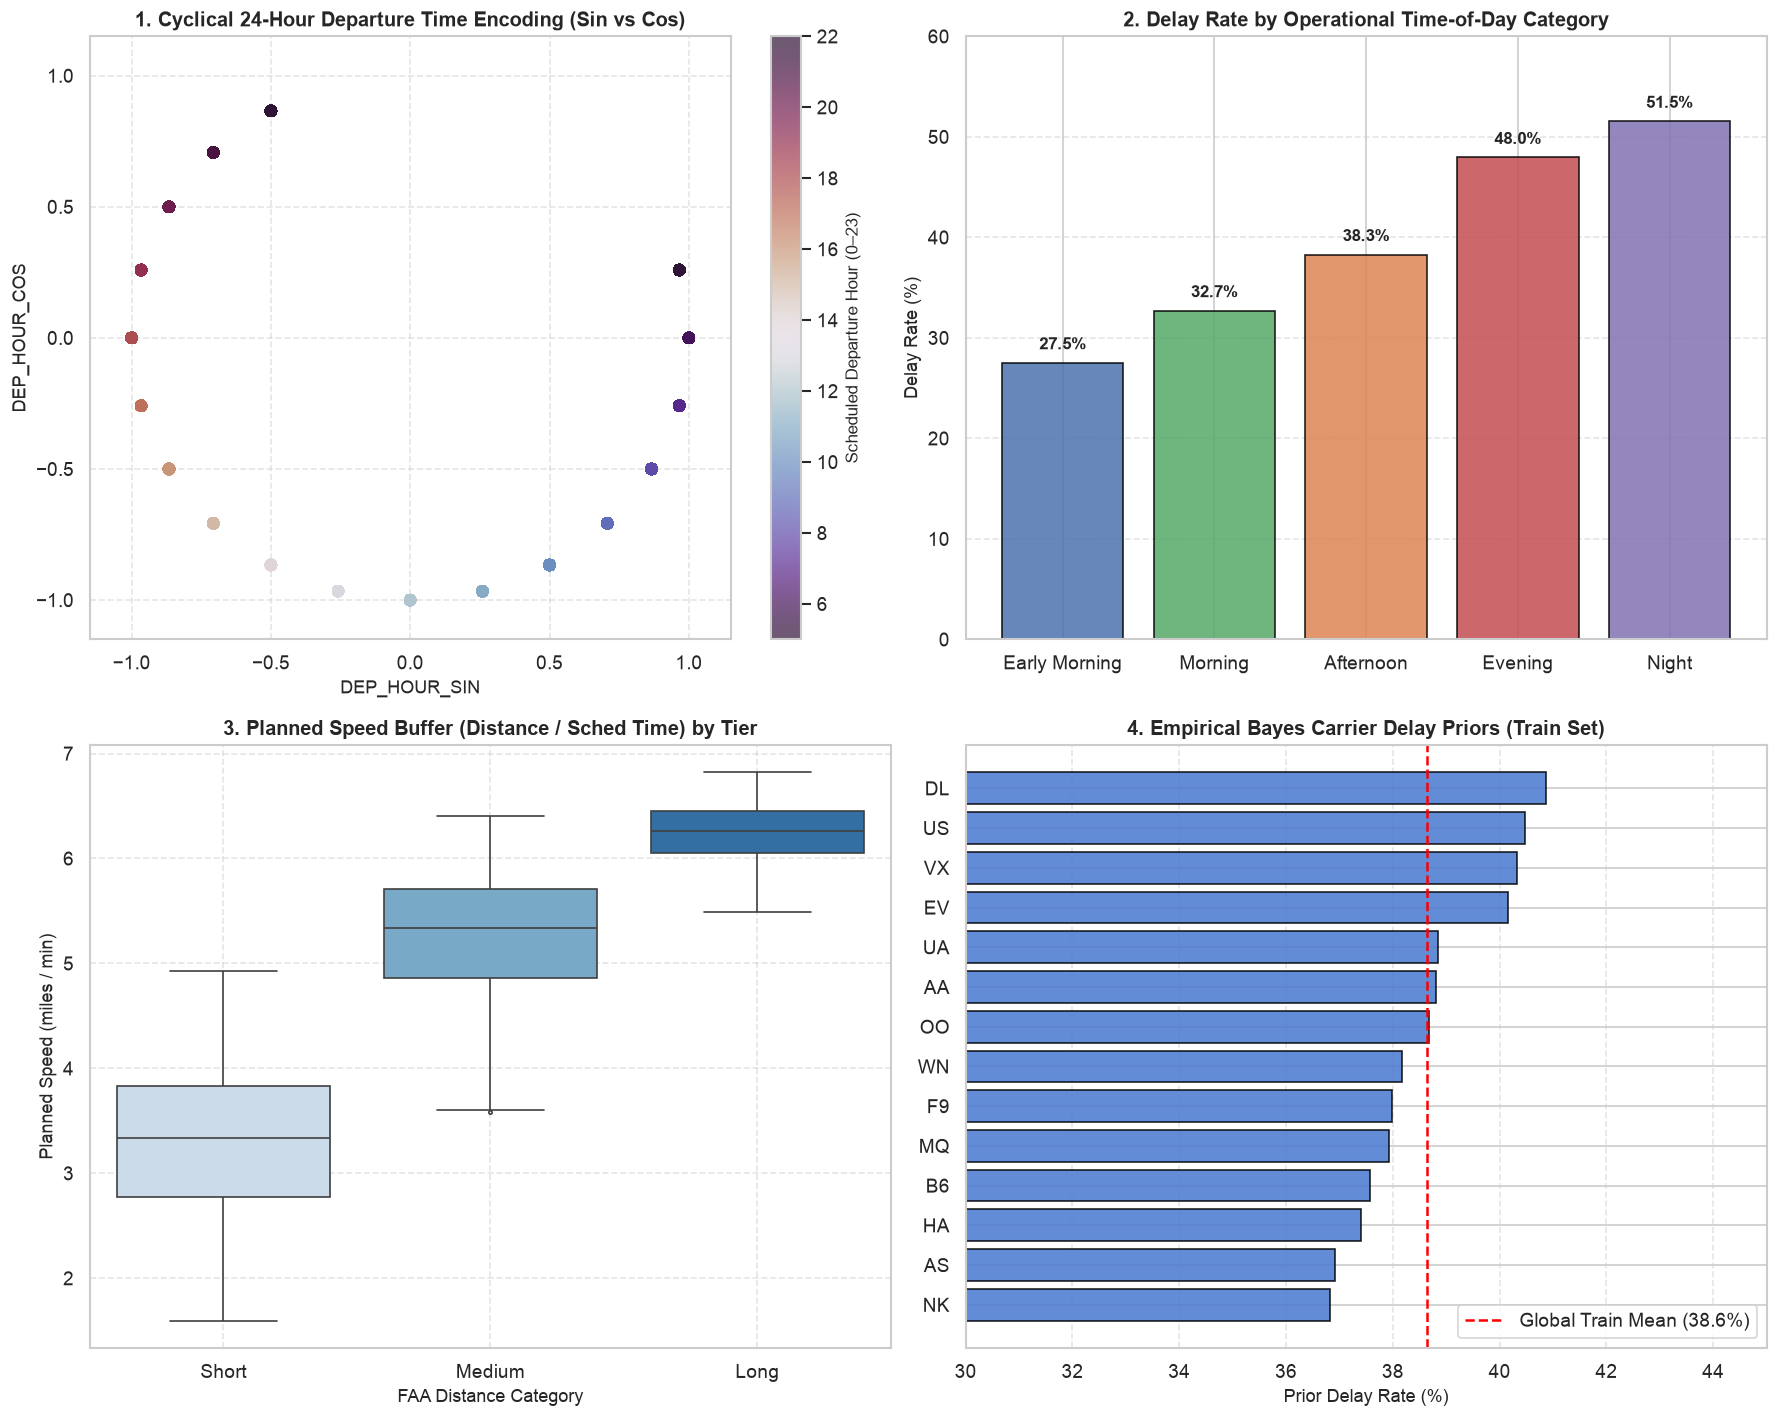

In [7]:
# ==============================================================================
# Cell 7: Generate Publication-Quality Visualizations
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Cyclical Departure Clock
ax1 = axes[0, 0]
scatter = ax1.scatter(
    df_features["DEP_HOUR_SIN"],
    df_features["DEP_HOUR_COS"],
    c=df_features["DEP_HOUR"],
    cmap="twilight_shifted",
    s=40,
    alpha=0.7
)
cbar = plt.colorbar(scatter, ax=ax1)
cbar.set_label("Scheduled Departure Hour (0–23)", fontsize=10)
ax1.set_title("1. Cyclical 24-Hour Departure Time Encoding (Sin vs Cos)", fontsize=12, fontweight="bold")
ax1.set_xlabel("DEP_HOUR_SIN", fontsize=11)
ax1.set_ylabel("DEP_HOUR_COS", fontsize=11)
ax1.set_xlim(-1.15, 1.15)
ax1.set_ylim(-1.15, 1.15)
ax1.grid(True, linestyle="--", alpha=0.5)

# 2. Delay Rate by Time of Day
ax2 = axes[0, 1]
tod_order = ["Early Morning", "Morning", "Afternoon", "Evening", "Night"]
tod_stats = df_features.groupby("DEP_TIME_OF_DAY")["DELAYED"].mean().reindex(tod_order) * 100
bars = ax2.bar(tod_stats.index, tod_stats.values, color=["#4c72b0", "#55a868", "#dd8452", "#c44e52", "#8172b3"], edgecolor="black", alpha=0.85)
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2.0, yval + 1.0, f"{yval:.1f}%", ha="center", va="bottom", fontweight="bold", fontsize=10)
ax2.set_title("2. Delay Rate by Operational Time-of-Day Category", fontsize=12, fontweight="bold")
ax2.set_ylabel("Delay Rate (%)", fontsize=11)
ax2.set_ylim(0, 60)
ax2.grid(axis="y", linestyle="--", alpha=0.5)

# 3. Planned Speed by Distance Tier
ax3 = axes[1, 0]
sns.boxplot(
    data=df_features,
    x="DISTANCE_CATEGORY",
    y="PLANNED_SPEED",
    order=["Short", "Medium", "Long"],
    palette="Blues",
    ax=ax3,
    fliersize=2
)
ax3.set_title("3. Planned Speed Buffer (Distance / Sched Time) by Tier", fontsize=12, fontweight="bold")
ax3.set_xlabel("FAA Distance Category", fontsize=11)
ax3.set_ylabel("Planned Speed (miles / min)", fontsize=11)
ax3.grid(True, linestyle="--", alpha=0.5)

# 4. Carrier Historical Delay Priors (Training Partition)
ax4 = axes[1, 1]
carrier_priors = df_features.groupby("AIRLINE")["CARRIER_HIST_DELAY_RATE"].mean().sort_values() * 100
bars4 = ax4.barh(carrier_priors.index, carrier_priors.values, color="#4878d0", edgecolor="black", alpha=0.85)
ax4.axvline(train_df["DELAYED"].mean() * 100, color="red", linestyle="--", label=f"Global Train Mean ({train_df['DELAYED'].mean()*100:.1f}%)")
ax4.set_title("4. Empirical Bayes Carrier Delay Priors (Train Set)", fontsize=12, fontweight="bold")
ax4.set_xlabel("Prior Delay Rate (%)", fontsize=11)
ax4.set_xlim(30, 45)
ax4.legend(loc="lower right")
ax4.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = FIGURES_EDA_DIR / "feature_engineering_overview.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"✓ Saved overview visualization to: {fig_path}")
plt.show()

---
## 7. Reusable Preprocessing Pipeline (Scikit-Learn ColumnTransformer)

### Safe Preprocessing Rule: Fit on Training Split ONLY
Imputers and scalers must never be fit on the entire dataset prior to splitting.
`src/features.py` provides `build_feature_pipeline()`:
- **Numeric Features ({len(FEATURE_COLUMNS_NUMERIC)} columns):** Imputed with median and scaled using `StandardScaler`.
- **Categorical Features ({len(FEATURE_COLUMNS_CATEGORICAL)} columns):** Imputed with `'UNKNOWN'` and encoded with `OneHotEncoder(handle_unknown='ignore')`.

Let us demonstrate how downstream members (Member 3 for Regression, Member 4 for Classification) will consume this pipeline.

In [8]:
# ==============================================================================
# Cell 8: Scikit-Learn Pipeline Fit and Transformation Demo
# ==============================================================================
# Isolate training, validation, and test splits
X_train = train_df[FEATURE_COLUMNS_ALL]
y_train_class = train_df["DELAYED"]
y_train_reg = train_df["ARRIVAL_DELAY"]

X_val = val_df[FEATURE_COLUMNS_ALL]
y_val_class = val_df["DELAYED"]

X_test = test_df[FEATURE_COLUMNS_ALL]
y_test_class = test_df["DELAYED"]

# Instantiate scikit-learn pipeline
preprocessor = build_feature_pipeline()

# FIT STRICTLY ON X_TRAIN ONLY
preprocessor.fit(X_train)
print("✓ ColumnTransformer fitted EXCLUSIVELY on training partition (X_train).")

# Transform X_train, X_val, X_test
X_train_trans = preprocessor.transform(X_train)
X_val_trans = preprocessor.transform(X_val)
X_test_trans = preprocessor.transform(X_test)

print(f"• X_train Transformed Shape: {X_train_trans.shape}")
print(f"• X_val   Transformed Shape: {X_val_trans.shape}")
print(f"• X_test  Transformed Shape: {X_test_trans.shape}")

# Verify no NaN or Inf in transformed matrices
assert not np.isnan(X_train_trans).any(), "NaN found in transformed X_train"
assert not np.isnan(X_val_trans).any(), "NaN found in transformed X_val"
assert not np.isnan(X_test_trans).any(), "NaN found in transformed X_test"
print("✓ All transformed feature matrices are strictly complete with zero NaNs or Infs.")

✓ ColumnTransformer fitted EXCLUSIVELY on training partition (X_train).
• X_train Transformed Shape: (16366, 83)
• X_val   Transformed Shape: (4114, 83)
• X_test  Transformed Shape: (4042, 83)
✓ All transformed feature matrices are strictly complete with zero NaNs or Infs.


---
## 8. Comprehensive Dataset Validation & Export

We execute `validate_feature_dataset()` to verify:
1. Row count matches input exactly (24,522 rows in = 24,522 rows out).
2. Zero duplicate rows.
3. Complete absence of prohibited data leakage columns in feature list.
4. Target isolation (`DELAYED` and `ARRIVAL_DELAY` strictly excluded from feature inputs).
5. Chronological boundary separation.
6. Zero unresolved nulls and zero infinite values.

Finally, we export the verified model-ready dataset to `data/processed/flights_features.csv`.

In [9]:
# ==============================================================================
# Cell 9: Comprehensive Validation and File Export
# ==============================================================================
audit_results = validate_feature_dataset(
    df=df_features,
    source_row_count=len(df_clean),
    feature_cols=FEATURE_COLUMNS_ALL
)

print("=" * 70)
print("COMPREHENSIVE VALIDATION AUDIT RESULTS:")
print("=" * 70)
for k, v in audit_results.items():
    print(f"• {k:<30}: {v}")
print("=" * 70)

# Export prepared dataset
output_features_csv = PROCESSED_DATA_DIR / "flights_features.csv"
df_features.to_csv(output_features_csv, index=False)

print(f"✓ Successfully exported model-ready feature dataset to:")
print(f"  {output_features_csv}")
print(f"  Total records: {len(df_features):,} rows | {len(df_features.columns)} columns")
print(f"  File size:     {output_features_csv.stat().st_size / (1024*1024):.2f} MB")

COMPREHENSIVE VALIDATION AUDIT RESULTS:
• row_count                     : 24522
• row_count_passed              : True
• duplicate_rows                : 0
• duplicate_check_passed        : True
• leakage_features_found        : []
• leakage_check_passed          : True
• target_isolation_passed       : True
• chronological_splits          : {'train': {'count': 16366, 'min_date': '2015-01-01', 'max_date': '2015-08-31'}, 'val': {'count': 4114, 'min_date': '2015-09-01', 'max_date': '2015-10-31'}, 'test': {'count': 4042, 'min_date': '2015-11-01', 'max_date': '2015-12-31'}}
• chronological_splits_passed   : True
• feature_integrity_passed      : True


✓ Successfully exported model-ready feature dataset to:
  /Users/suryansh/Desktop/video/Flight_Delay_Prediction/data/processed/flights_features.csv
  Total records: 24,522 rows | 46 columns
  File size:     9.53 MB


---
## 9. Summary and Handoff Directives for Member 3

### Deliverables Produced:
1. **Interactive Notebook:** `notebooks/03b_feature_engineering.ipynb` (this notebook).
2. **Reusable Python Module:** `src/features.py` containing feature engineering functions, Empirical Bayes estimators, ColumnTransformer builders, and validation checks.
3. **Prepared Feature Dataset:** `data/processed/flights_features.csv` (24,522 rows, 46 columns, containing partition indicator `SPLIT_SET`).
4. **Engineering Report:** `reports/member2B_feature_engineering_report.md`.
5. **Handoff Documentation:** `reports/member2B_handoff.md`.

### Next Step — Member 3 (Linear & Logistic Regression Benchmarks):
- Ingest `data/processed/flights_features.csv`.
- Filter `SPLIT_SET == 'train'` for training, `SPLIT_SET == 'val'` for validation, `SPLIT_SET == 'test'` for final evaluation.
- Separate target vector: `y_train = train['DELAYED']` (or `train['ARRIVAL_DELAY']` for continuous regression).
- Fit `build_feature_pipeline()` strictly on training features `X_train = train[FEATURE_COLUMNS_ALL]`.
- Establish OLS Linear Regression and Logistic Regression baselines compliant with the AML Phase 1 syllabus.